本 notebook 是 [M05.5 卷积网络与视觉](../notes/05-convolutional-networks.qmd) 的实例讲解。

1. 1. 从零互相关与 Conv2d 对齐
2. 2. 感受野与残差梯度通路
3. 3. CPU 合成晶圆模式分类
4. 4. 冻结特征与线性探针

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

运行前安装已声明依赖：`uv sync --locked --extra perf --extra data --extra dl`。本例使用 CPU，不需外部数据或预训练权重。

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from semiai.plotting import use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 从零互相关与 Conv2d 对齐

用显式窗口相乘求和实现单通道二维互相关，确认框架没有翻转卷积核。

In [2]:
torch.set_num_threads(1)
torch.manual_seed(42)
image = rng.normal(size=(6, 6))
kernel = rng.normal(size=(3, 3))
manual = np.array(
    [[np.sum(image[i : i + 3, j : j + 3] * kernel) for j in range(4)] for i in range(4)]
)
reference = nn.functional.conv2d(torch.tensor(image)[None, None], torch.tensor(kernel)[None, None])[
    0, 0
].numpy()
print("互相关最大差:", np.max(np.abs(manual - reference)), "输出形状:", manual.shape)
assert np.allclose(manual, reference, atol=1e-12)

互相关最大差: 8.881784197001252e-16 输出形状: (4, 4)


读法：深度学习的 Conv2d 实际使用互相关，核由训练学习；比较手写实现必须统一 padding、stride、dilation、通道和核布局。

## 2. 感受野与残差梯度通路

两层卷积以全正权重避免 ReLU 掩蔽，反传单个输出来核验理论感受野；再检查零残差分支的恒等映射。

In [3]:
x = torch.ones(1, 1, 15, 15, requires_grad=True)
network = nn.Sequential(
    nn.Conv2d(1, 1, 3, stride=2, padding=1, bias=False),
    nn.ReLU(),
    nn.Conv2d(1, 1, 3, padding=1, bias=False),
)
with torch.no_grad():
    for p in network.parameters():
        p.fill_(1.0)
out = network(x)
out[0, 0, 4, 4].backward()
indices = torch.nonzero(x.grad[0, 0])
extent = indices.max(0).values - indices.min(0).values + 1
print("非零输入梯度范围:", indices.min(0).values, indices.max(0).values, "跨度:", extent)
assert torch.equal(extent, torch.tensor([7, 7]))


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
        )

    def forward(self, x):
        return x + self.branch(x)


block = ResidualBlock(2)
with torch.no_grad():
    for p in block.parameters():
        p.zero_()
x = torch.randn(1, 2, 6, 6, requires_grad=True)
output = block(x)
output.sum().backward()
print(
    "零分支恒等误差:", (output - x).abs().max().item(), "梯度误差:", (x.grad - 1).abs().max().item()
)
assert torch.equal(output, x) and torch.equal(x.grad, torch.ones_like(x))

非零输入梯度范围: tensor([5, 5]) tensor([11, 11]) 跨度: tensor([7, 7])
零分支恒等误差: 0.0 梯度误差: 0.0


读法：理论感受野是可能依赖的区域，实际有效梯度还受权重和激活影响；这里的恒等检查不等于证明任意深 ResNet 都不会梯度消失。

## 3. CPU 合成晶圆模式分类

独立生成训练与评价图，训练一个小 CNN，输出损失、准确率和混淆矩阵；数据只模拟形状，不是 WM-811K。

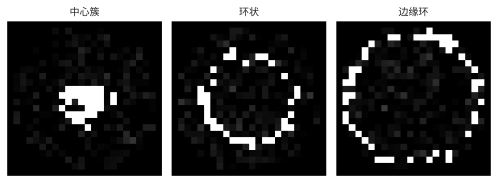

首末训练 CE: 0.9720068589846294 5.2713680148978406e-05 独立合成集准确率: 1.0
混淆矩阵:
 [[40  0  0]
 [ 0 40  0]
 [ 0  0 40]] 多数类基线: 0.3333333333333333


In [4]:
def make_patterns(per_class, seed):
    local = np.random.default_rng(seed)
    images = []
    labels = []
    coordinate = np.linspace(-1, 1, 24)
    xx, yy = np.meshgrid(coordinate, coordinate)
    radius = np.sqrt(xx * xx + yy * yy)
    wafer = radius <= 1
    for label in range(3):
        for _ in range(per_class):
            image = local.normal(0, 0.07, (24, 24))
            angle = local.uniform(0, 2 * np.pi, 55)
            r = np.clip(
                local.normal([0.2, 0.6, 0.88][label], [0.09, 0.035, 0.025][label], 55), 0, 0.97
            )
            px = np.clip(np.rint((r * np.cos(angle) + 1) * 11.5).astype(int), 0, 23)
            py = np.clip(np.rint((r * np.sin(angle) + 1) * 11.5).astype(int), 0, 23)
            image[py, px] = 1.0
            images.append((image * wafer).astype(np.float32))
            labels.append(label)
    order = local.permutation(len(labels))
    return np.array(images)[order, None, :, :], np.array(labels)[order]


images, labels = make_patterns(3, 42)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, label, title in zip(axes, range(3), ["中心簇", "环状", "边缘环"], strict=True):
    image = images[np.flatnonzero(labels == label)[0], 0]
    ax.imshow(image, cmap="gray", vmin=0, vmax=1, origin="lower")
    ax.set(title=title)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

train_x, train_y = make_patterns(100, 1)
test_x, test_y = make_patterns(40, 2026)
train = TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y))
loader = DataLoader(train, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42))


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 12, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
        )
        self.head = nn.Linear(12 * 6 * 6, 3)

    def forward(self, x):
        return self.head(self.features(x))


model = SmallCNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
history = []
for _ in range(10):
    model.train()
    total = 0.0
    for x, y in loader:
        # 旋转不改变这三个径向模式类别；仅用于训练样本。
        x = torch.rot90(x, int(torch.randint(4, ()).item()), dims=(-2, -1))
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(x)
    history.append(total / len(train))
model.eval()
with torch.inference_mode():
    predicted = model(torch.from_numpy(test_x)).argmax(1).numpy()
print("首末训练 CE:", history[0], history[-1], "独立合成集准确率:", np.mean(predicted == test_y))
print(
    "混淆矩阵:\n",
    confusion_matrix(test_y, predicted),
    "多数类基线:",
    np.bincount(test_y).max() / len(test_y),
)
assert history[-1] < history[0]

读法：训练和测试来自独立随机图，旋转在此标签定义下保持类别；指标只刻画这个合成生成器，不支持真实晶圆缺陷或跨设备泛化结论。

## 4. 冻结特征与线性探针

复用上一节训练得到的卷积特征，只在新合成样本上拟合线性头，检查 backbone 没有被更新。

In [5]:
backbone = copy.deepcopy(model.features).eval()
for p in backbone.parameters():
    p.requires_grad_(False)
before = [p.detach().clone() for p in backbone.parameters()]
new_x, new_y = make_patterns(30, 99)
with torch.no_grad():
    features = backbone(torch.from_numpy(new_x))
    test_features = backbone(torch.from_numpy(test_x))
head = nn.Linear(features.shape[1], 3)
optimizer = torch.optim.Adam(head.parameters(), lr=0.03)
for _ in range(100):
    optimizer.zero_grad(set_to_none=True)
    loss = nn.functional.cross_entropy(head(features), torch.from_numpy(new_y))
    loss.backward()
    optimizer.step()
with torch.no_grad():
    accuracy = (head(test_features).argmax(1) == torch.from_numpy(test_y)).float().mean().item()
unchanged = all(
    torch.equal(old, new) for old, new in zip(before, backbone.parameters(), strict=True)
)
print("冻结特征探针准确率:", accuracy, "backbone 完全不变:", unchanged)
assert unchanged and all(p.grad is None for p in backbone.parameters())

冻结特征探针准确率: 1.0 backbone 完全不变: True


读法：这是同一合成任务上的特征复用机制，未下载预训练权重，不构成真实跨域迁移实验。实际迁移还需比较从头训练、冻结与分层微调，并处理源域统计和标签差异。

## 小结

CNN 的价值来自网格局部性、权重共享和多尺度组合。尺寸与感受野描述信息路径，残差通路改善优化结构，增强与迁移表达任务偏好。先用小实例核验机制，再在严格来源边界下评价真实图像，才能把形状识别分数连接到材料任务。